<div style="background-color:#000;"><img src="pqn.png"></img></div><div><a href="https://pyquantnews.com/">PyQuant News</a> is where finance practitioners level up with Python for quant finance, algorithmic trading, and market data analysis. Looking to get started? Check out the fastest growing, top-selling course to <a href="https://www.pyquantnews.com/getting-started-with-python-for-quant-finance/">get started with Python for quant finance</a>. For educational purposes. Not investment advice. Use at your own risk.</div>

## Library installation

This installs VectorBT PRO and the libraries that it calls for the price download and for the image files.

In [ ]:
!pip install yfinance kaleido imageio "vectorbtpro[base] @ git+https://$GITHUB_TOKEN@github.com/polakowo/vectorbt.pro.git"

VectorBT PRO is a paid package that is not on PyPI, so this command installs vectorbtpro from the private GitHub repository for your VBT PRO license. Before you run this cell, set the GITHUB_TOKEN environment variable to a GitHub token with access to that repository.

## Imports and setup

We use VectorBT PRO (VBT) for every step of the analysis, from the price download to the GIF. The dark theme sets the colors of every chart in the notebook.

In [1]:
import vectorbtpro as vbt

In [2]:
vbt.settings.set_theme("dark")

## Download one year of hourly prices

We set each parameter of the analysis once, then pull hourly BTC-USD bars for the last year from Yahoo Finance through yfinance. A bar is the price record for one hour.

In [3]:
SYMBOL = "BTC-USD"
TIMEFRAME = "1 hour"
START = "one year ago"

In [4]:
LAST_N_BARS = 66
PRED_N_BARS = 12
MIN_PATTERNS = 3

In [5]:
GIF_FNAME = "projections.gif"
GIF_N_BARS = 72
GIF_FPS = 4
GIF_PAD = 0.01

In [6]:
data = vbt.YFData.pull(SYMBOL, timeframe=TIMEFRAME, start=START)

LAST_N_BARS sets the pattern length at 66 hours, and PRED_N_BARS sets each projection at 12 hours. START is a relative date, so each run pulls the most recent year. GIF_N_BARS limits the animation to the last 72 bars, and GIF_PAD adds a 1% margin to the price axis.

## Find and project similar price patterns

This function uses the last LAST_N_BARS of the typical price as the pattern and searches the full history for similar segments. The typical price, hlc3 in VBT, equals (high + low + close) / 3 for each bar.

In [7]:
def find_patterns(data):
    price = data.hlc3
    pattern = price.values[-LAST_N_BARS:]
    pattern_ranges = price.vbt.find_pattern(
        pattern=pattern,
        rescale_mode="rebase",
        overlap_mode="allow",
        wrapper_kwargs=dict(freq=TIMEFRAME),
    )
    pattern_ranges = pattern_ranges.status_closed
    return pattern_ranges

In [8]:
pattern_ranges = find_patterns(data)

In [9]:
print("Matched segments:", pattern_ranges.count())

Matched segments: 7


With rescale_mode="rebase", VBT compares each segment by its percent change from its own first bar, so a match at a lower price level still counts. The function keeps only closed ranges, so the latest segment does not match itself. The printed count tells us how many past segments feed the projections in the next block.

This function extends each matched segment by the PRED_N_BARS that came after it and plots those paths forward from the last bar. The call adds bands around the paths so we can see their spread.

In [10]:
def plot_projections(data, pattern_ranges, **kwargs):
    projection_ranges = pattern_ranges.with_delta(
        PRED_N_BARS,
        open=data.open,
        high=data.high,
        low=data.low,
        close=data.close,
    )
    projection_ranges = projection_ranges.status_closed
    fig = projection_ranges.plot_projections(
        plot_past_period=LAST_N_BARS,
        **kwargs,
    )
    fig.update_layout(
        title=f"{SYMBOL} price projections ({PRED_N_BARS} bars ahead)",
        xaxis_title="Date",
        yaxis_title="Price (USD)",
    )
    return fig

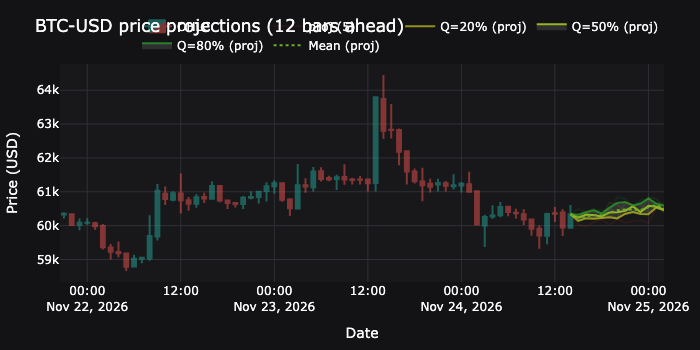

In [11]:
plot_projections(data, pattern_ranges, plot_bands=True).show_png()

The bands run from the 20th to the 80th percentile of the paths (the VBT default), so 60% of the paths lie between them. A match too close to the last bar has no full 12 hours after it, so the function drops it. These paths show what happened after similar setups in the past, and no test in this notebook measures them as a forecast.

<a href="https://pyquantnews.com/">PyQuant News</a> is where finance practitioners level up with Python for quant finance, algorithmic trading, and market data analysis. Looking to get started? Check out the fastest growing, top-selling course to <a href="https://www.pyquantnews.com/getting-started-with-python-for-quant-finance/">get started with Python for quant finance</a>. For educational purposes. Not investment advice. Use at your own risk.